# 07 Uncertainty calibration
Split conformal calibration, fitted on the **calibration split only** (6 skulls, 48 views). The test split is used for reporting only.
Scopes: global, per-coordinate, per-region, subject-level (simultaneous). Pointwise coverage is never reported as simultaneous coverage.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
r = json.load(open(RES + '/results.json'))
cal = json.load(open(RES + '/calibrator_global.json'))
print('global conformal scale factors q (multiply the predicted std):', {k: round(v, 3) for k, v in cal['q'].items()}, '| n scores:', cal['n_scores'])
print(f"{'level':>6} {'raw cov':>9} {'calibrated':>11} {'raw halfwidth mm':>17} {'cal halfwidth mm':>17} {'simult (raw)':>13}")
for l in ['50', '80', '90', '95']:
    raw, g = r['calibration']['raw'][l], r['calibration']['global']['test'][l]
    print(f"{l:>6} {raw['pointwise']:9.3f} {g['pointwise']:11.3f} {raw['mean_half_width_mm']:17.2f} {g['mean_half_width_mm']:17.2f} {raw['simultaneous']:13.3f}")

global conformal scale factors q (multiply the predicted std): {'0.5': 0.476, '0.8': 0.998, '0.9': 1.383, '0.95': 1.746} | n scores: 301680
 level   raw cov  calibrated  raw halfwidth mm  cal halfwidth mm  simult (raw)
    50     0.663       0.509              2.52              1.78         0.000
    80     0.891       0.813              4.80              3.74         0.000
    90     0.948       0.910              6.16              5.18         0.000
    95     0.975       0.959              7.34              6.54         0.146


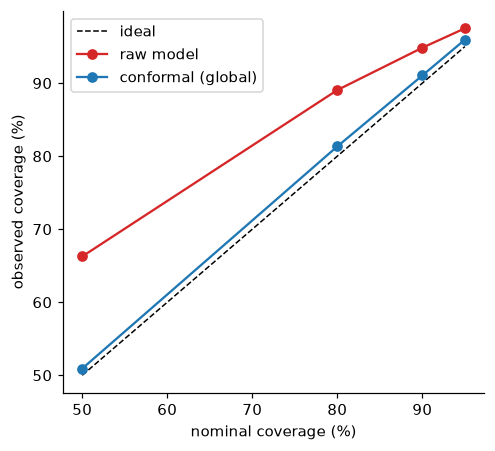

In [3]:
lv = [50, 80, 90, 95]
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([50, 95], [50, 95], 'k--', lw=1, label='ideal')
ax.plot(lv, [100 * r['calibration']['raw'][str(l)]['pointwise'] for l in lv], 'o-', c='tab:red', label='raw model')
ax.plot(lv, [100 * r['calibration']['global']['test'][str(l)]['pointwise'] for l in lv], 'o-', c='tab:blue', label='conformal (global)')
ax.set_xlabel('nominal coverage (%)'); ax.set_ylabel('observed coverage (%)'); ax.legend(); plt.tight_layout(); plt.show()

In [4]:
u = r['uncertainty_raw']
print('raw CRPS (mm): %.3f | NLL: %.3f | standardised residual mean/std: %.3f / %.3f' % (u['crps_mm'], u['nll'], u['z_mean'], u['z_std']))
print('calibration error (mean |observed - nominal|):', round(u['coverage']['ece_coverage'], 3))
print('subject-level simultaneous coverage, subject_max scope:', {l: round(r['calibration']['subject_max']['test'][l]['simultaneous'], 3) for l in ['50', '80', '90', '95']})
print('note: with few calibration skulls the highest simultaneous levels become conservative or infinite.')

raw CRPS (mm): 1.725 | NLL: 2.495 | standardised residual mean/std: 0.006 / 0.798
calibration error (mean |observed - nominal|): 0.082
subject-level simultaneous coverage, subject_max scope: {'50': 0.938, '80': 1.0, '90': 1.0, '95': 1.0}
note: with few calibration skulls the highest simultaneous levels become conservative or infinite.


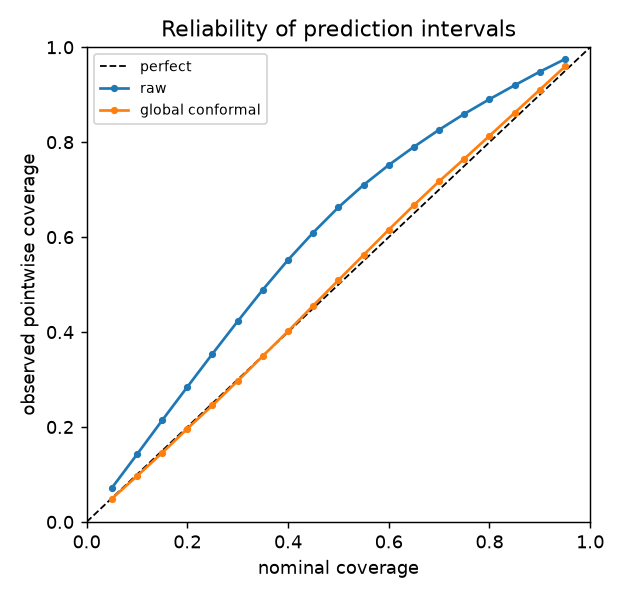

In [5]:
from IPython.display import Image, display
display(Image(RES + '/reliability.png'))